In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to Python path
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data_loader import load_cmapss_data

# Plot settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Load FD001
train_df, test_df, rul_df = load_cmapss_data("FD001")

print("Dataset loaded successfully!")
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)
print("RUL shape:", rul_df.shape)

Dataset loaded successfully!
Training shape: (20631, 26)
Testing shape: (13096, 26)
RUL shape: (100, 1)


In [2]:
# Display first five records
display(train_df.head())

# Dataset information
train_df.info()

# Statistical summary
display(train_df.describe().T)

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   engine_id  20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   sensor_1   20631 non-null  float64
 6   sensor_2   20631 non-null  float64
 7   sensor_3   20631 non-null  float64
 8   sensor_4   20631 non-null  float64
 9   sensor_5   20631 non-null  float64
 10  sensor_6   20631 non-null  float64
 11  sensor_7   20631 non-null  float64
 12  sensor_8   20631 non-null  float64
 13  sensor_9   20631 non-null  float64
 14  sensor_10  20631 non-null  float64
 15  sensor_11  20631 non-null  float64
 16  sensor_12  20631 non-null  float64
 17  sensor_13  20631 non-null  float64
 18  sensor_14  20631 non-null  float64
 19  sensor_15  20631 non-null  float64
 20  sensor_16  20631 

,count,mean,std,min,25%,50%,75%,max
engine_id,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200


In [3]:
print("Missing values:")
print(train_df.isnull().sum().sum())

print("\nDuplicate records:")
print(train_df.duplicated().sum())

print("\nNumber of unique engines:")
print(train_df["engine_id"].nunique())

print("\nTotal operating cycles:")
print(train_df["cycle"].max())

Missing values:
0

Duplicate records:
0

Number of unique engines:
100

Total operating cycles:
362


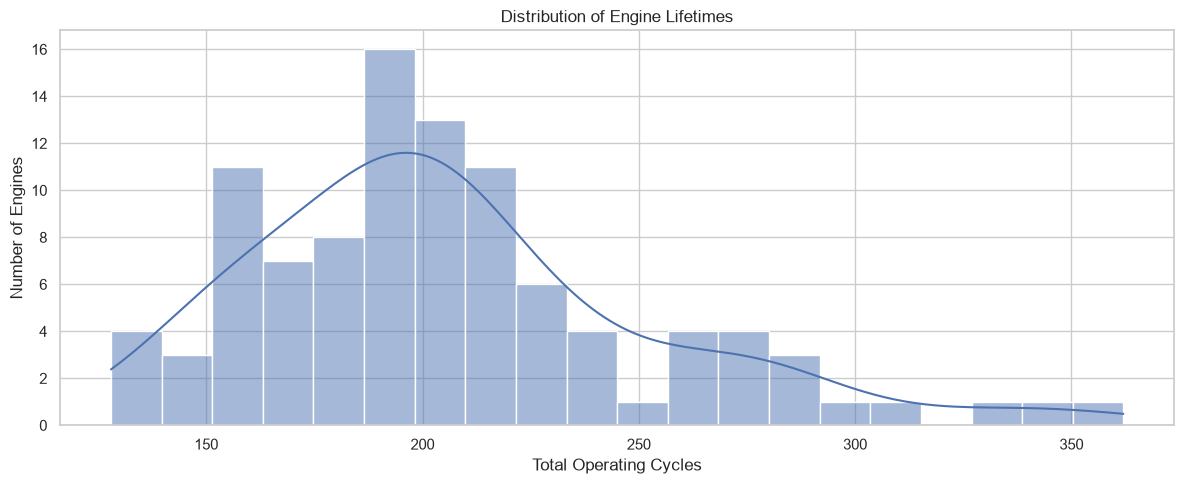

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


In [4]:
engine_life = (
    train_df.groupby("engine_id")["cycle"]
    .max()
)

plt.figure(figsize=(12, 5))

sns.histplot(
    engine_life,
    bins=20,
    kde=True
)

plt.title("Distribution of Engine Lifetimes")
plt.xlabel("Total Operating Cycles")
plt.ylabel("Number of Engines")

plt.tight_layout()
plt.show()

print(engine_life.describe())

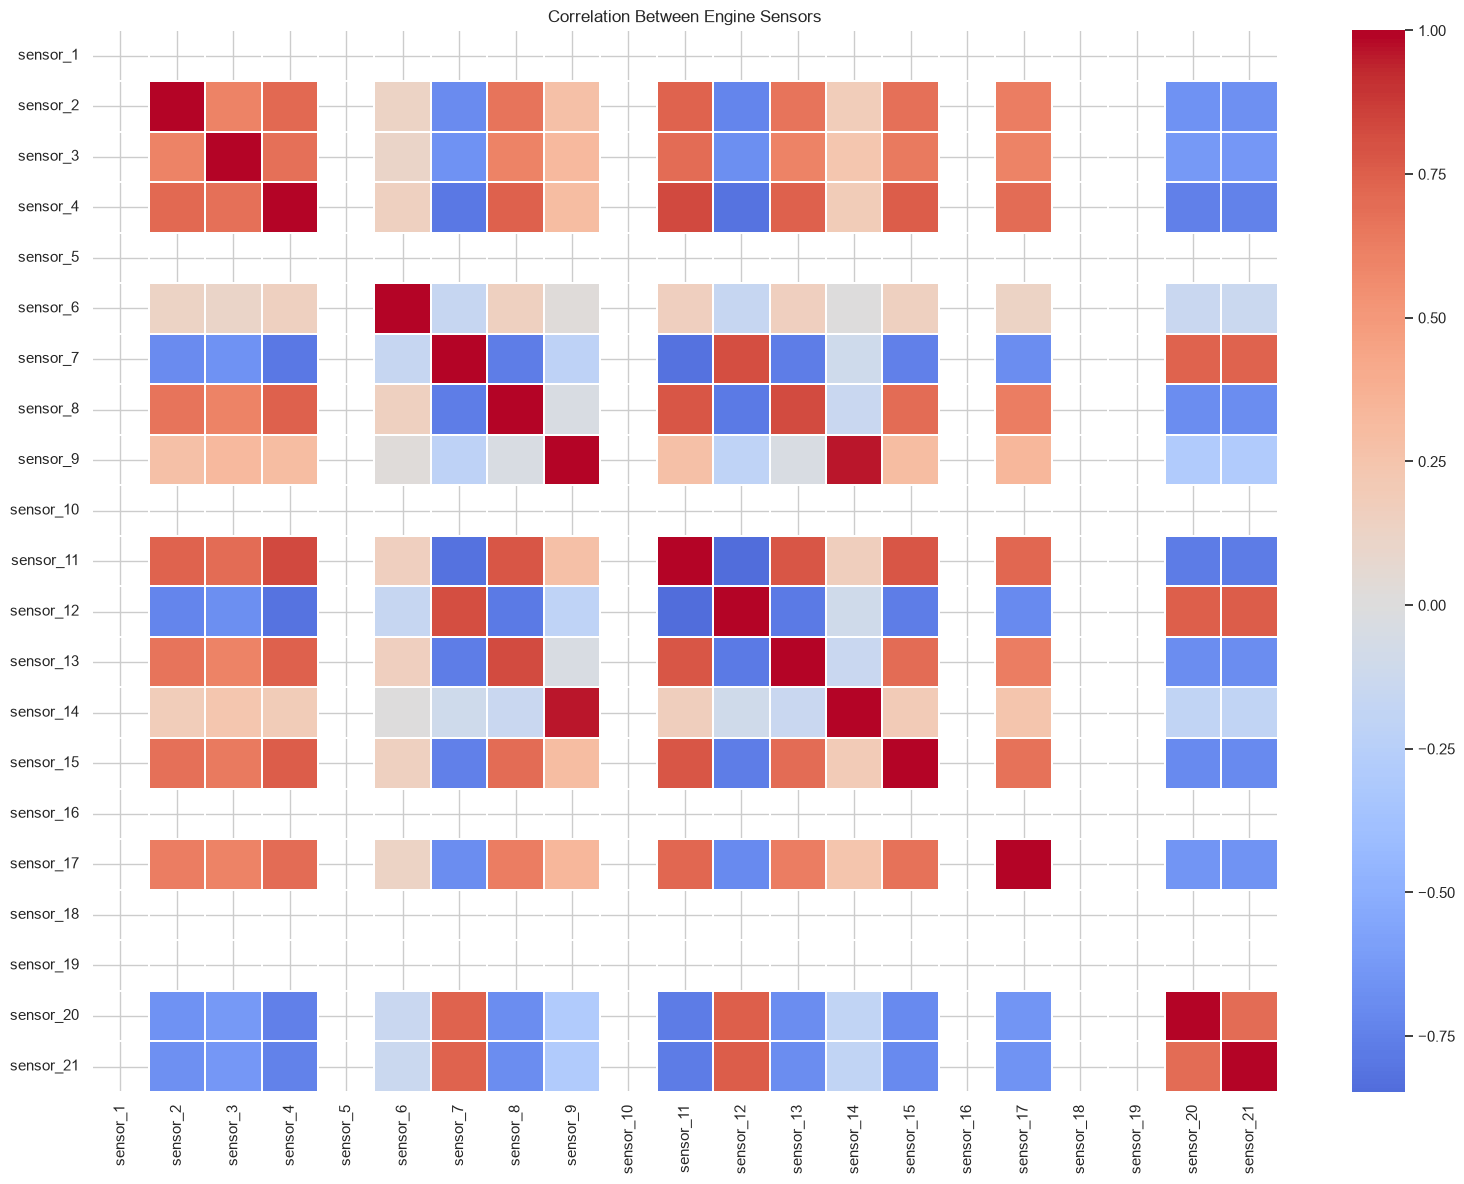

In [5]:
sensor_columns = [
    f"sensor_{i}" for i in range(1, 22)
]

correlation_matrix = train_df[
    sensor_columns
].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

plt.title("Correlation Between Engine Sensors")
plt.tight_layout()
plt.show()

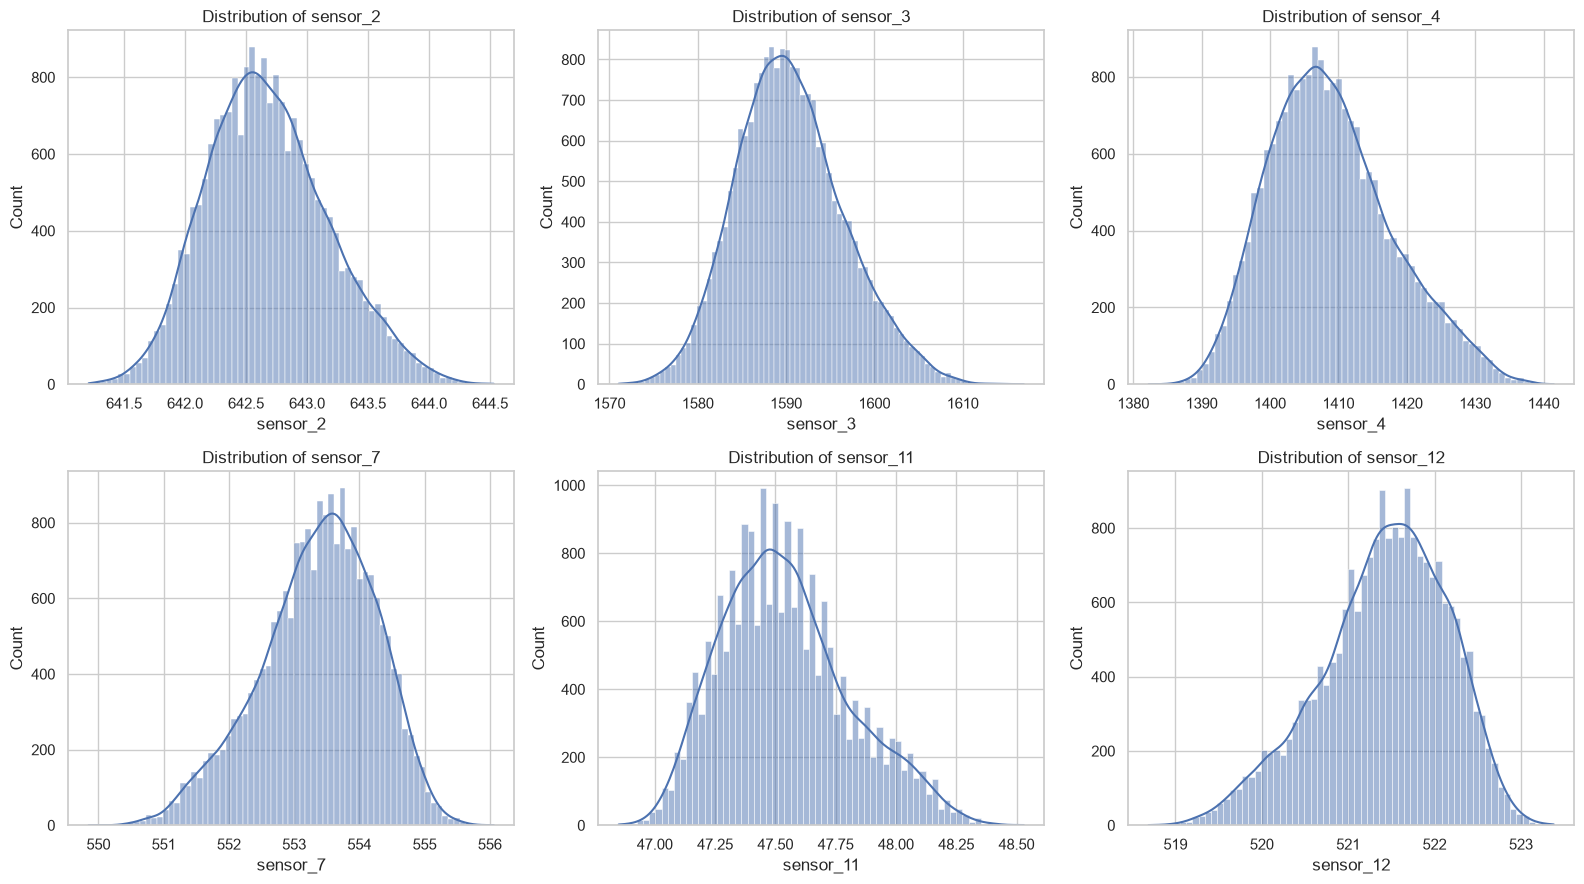

In [6]:
selected_sensors = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_11",
    "sensor_12"
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9)
)

for sensor, ax in zip(selected_sensors, axes.flatten()):

    sns.histplot(
        train_df[sensor],
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {sensor}")

plt.tight_layout()
plt.show()

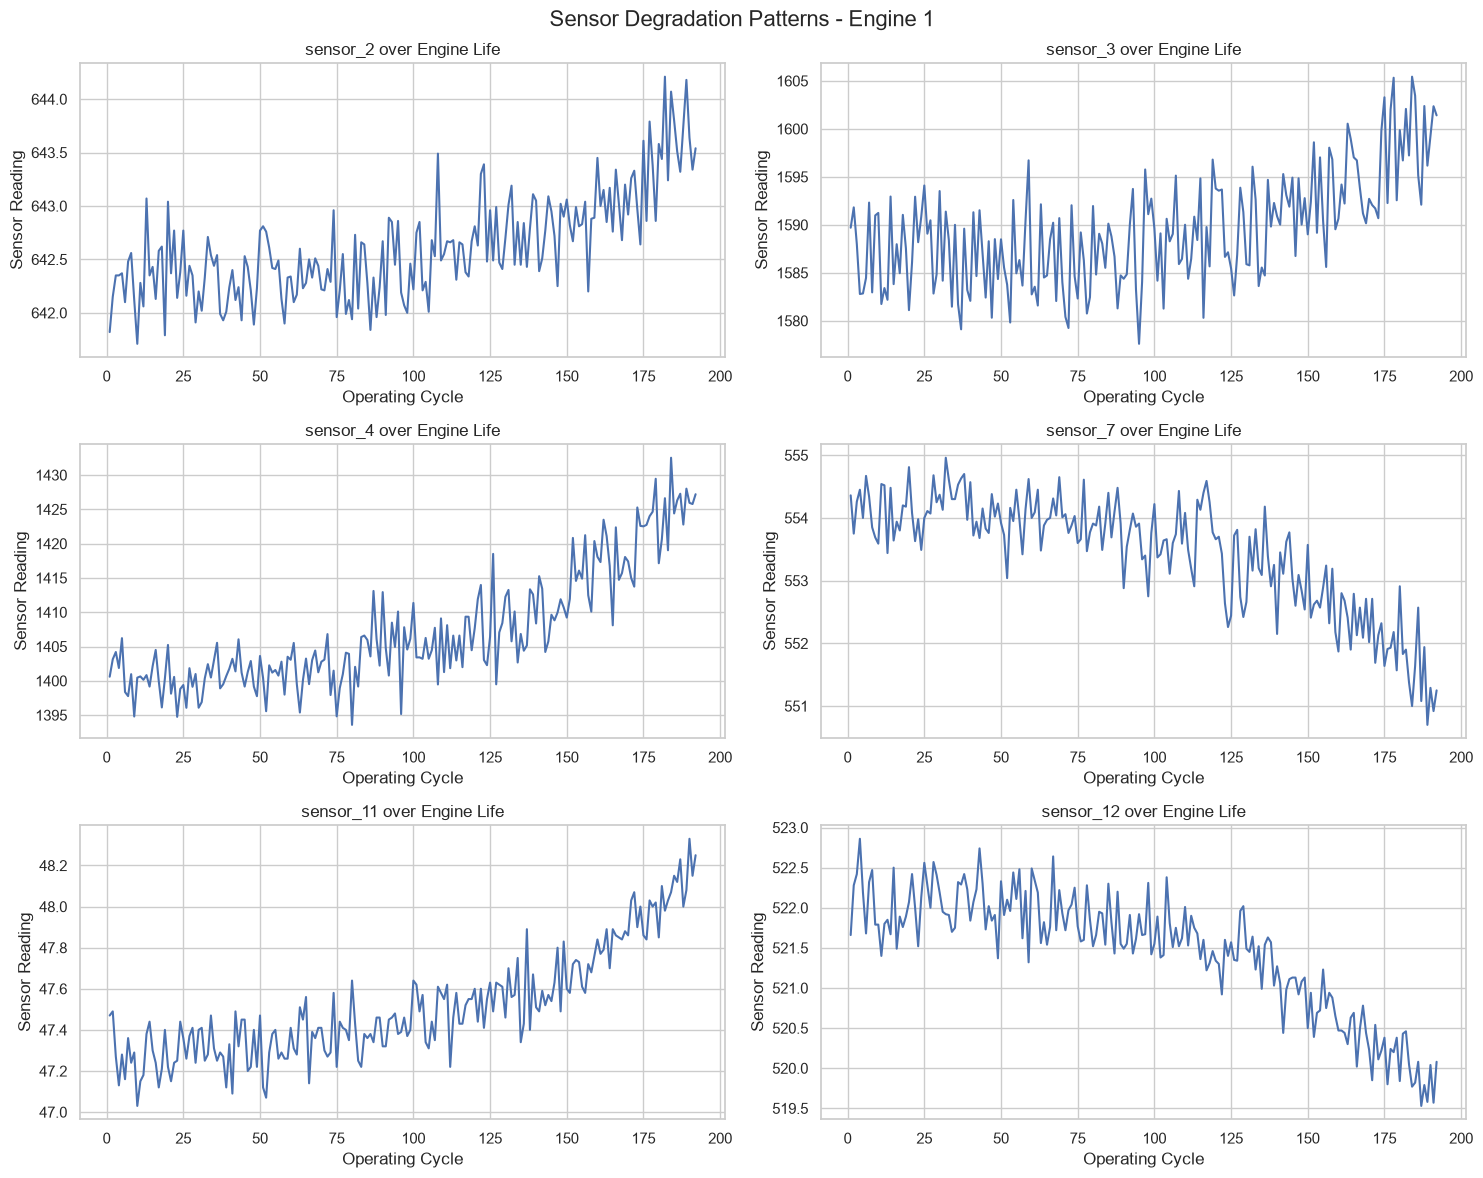

In [7]:
engine_id = 1

engine_data = train_df[
    train_df["engine_id"] == engine_id
]

selected_sensors = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_11",
    "sensor_12"
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(15, 12)
)

for sensor, ax in zip(
    selected_sensors,
    axes.flatten()
):

    ax.plot(
        engine_data["cycle"],
        engine_data[sensor]
    )

    ax.set_title(f"{sensor} over Engine Life")
    ax.set_xlabel("Operating Cycle")
    ax.set_ylabel("Sensor Reading")

plt.suptitle(
    "Sensor Degradation Patterns - Engine 1",
    fontsize=16
)

plt.tight_layout()
plt.show()

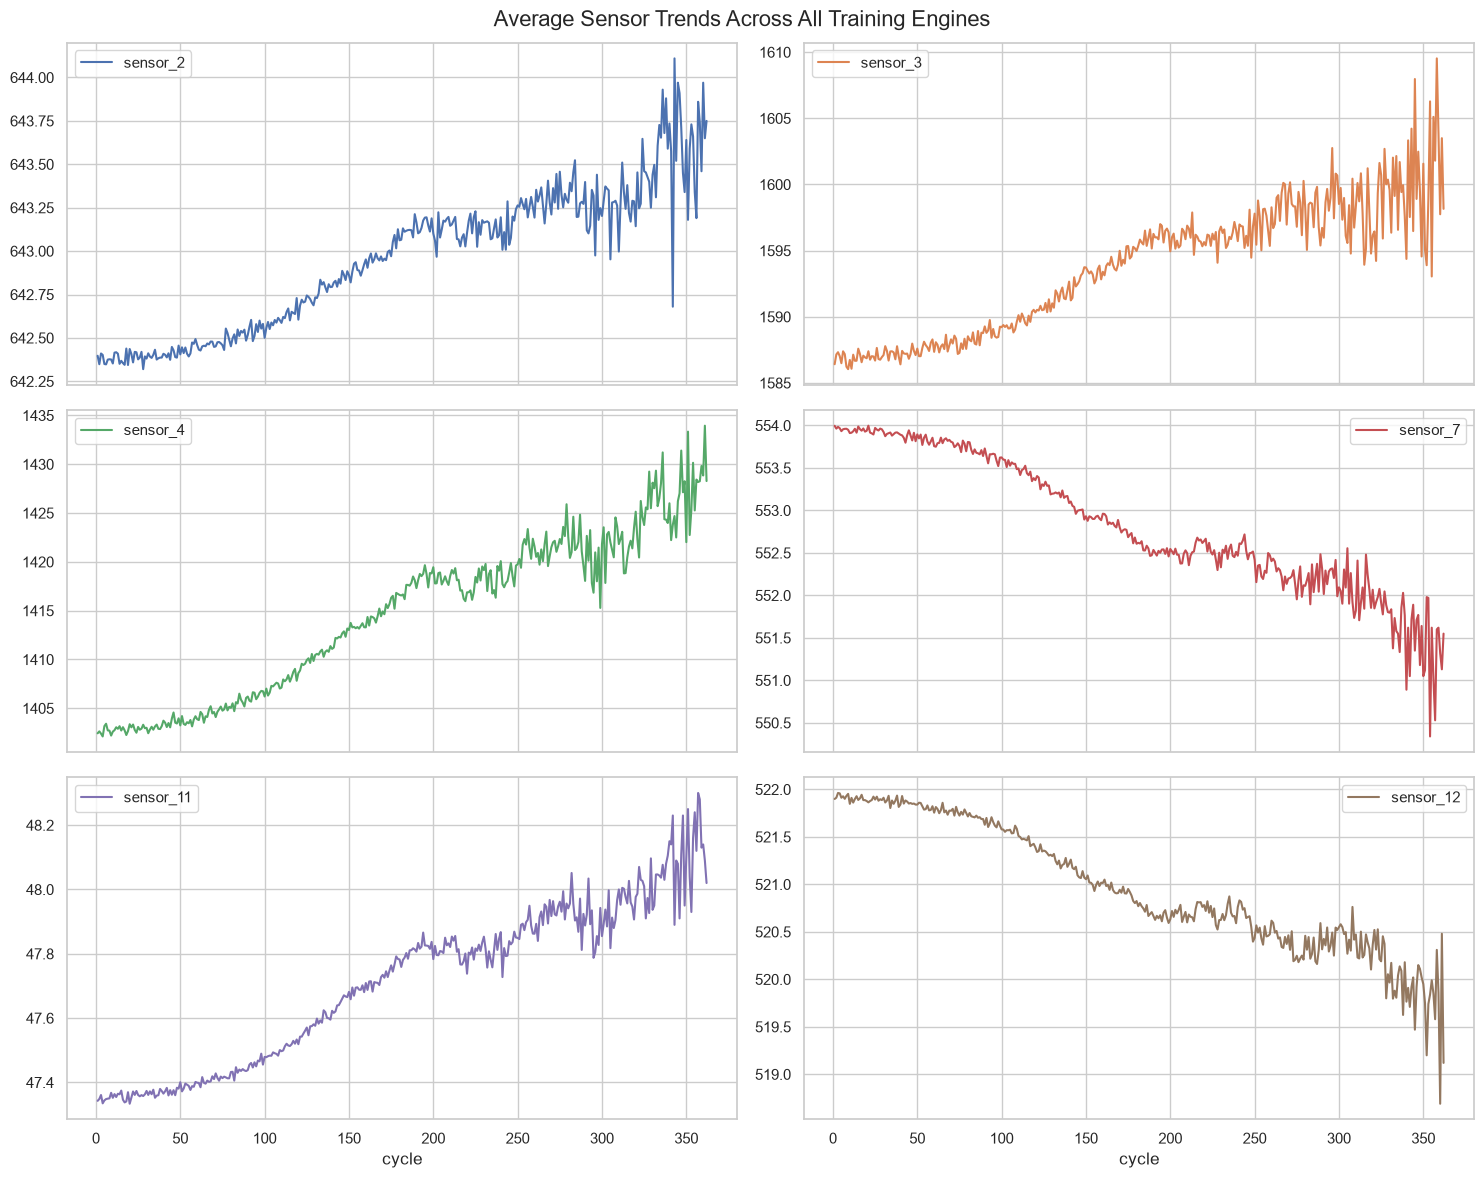

In [8]:
# Calculate average sensor readings at each operating cycle
average_sensor_trends = (
    train_df.groupby("cycle")[selected_sensors]
    .mean()
)

average_sensor_trends.plot(
    subplots=True,
    layout=(3, 2),
    figsize=(15, 12),
    sharex=True
)

plt.suptitle(
    "Average Sensor Trends Across All Training Engines",
    fontsize=16
)

plt.tight_layout()
plt.show()